<a href="https://colab.research.google.com/github/miguelcuero-ai/Fisica-computacional-2026-2/blob/main/Taller%204/Taller_4_FC_Numeros_Aleatorios.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Parte A — Funciones de la simulación

Complete las tres funciones de la siguiente celda:

1. `generar_paso(rng,a)`: consuma **un** número del generador recibido y devuelva $+a$ o $-a$.
2. `caminar(N,a,rng)`: valide $N\geq0$ y $a>0$; devuelva **$N+1$ posiciones**, incluida $x_0=0$.
3. `simular_caminatas(K,N,a,semilla,generador=None)`: valide $K>0$, $N\geq0$ y $a>0$. Si `generador` es `None`, cree **un solo** `random.Random(semilla)` al inicio; si se entrega un generador, úselo en su lugar (lo necesitará en la Parte D). Pase ese mismo generador a cada caminata y acumule $x_n$ y $x_n^2$ para todos los $n$.
4. Divida cada suma por $K$ **después** del ciclo sobre caminantes. Devuelva `(media_x, media_x2)`.

Use `ValueError` para parámetros inválidos. No reinicie la semilla dentro del ciclo de caminantes: eso repetiría la misma trayectoria $K$ veces.

<div style="background-color:#eef7ee; border-left:5px solid #4caf50; padding:10px 15px; margin:10px 0;"><b>Prueba manual:</b> para <code>N=0</code>, la trayectoria y ambos promedios deben contener solamente el cero inicial.</div>

In [1]:
import random

def generar_paso(rng, a):
    """Obtiene un número aleatorio u en [0, 1) y devuelve un paso +a o -a."""
    u = rng.random()
    return a if u < 0.5 else -a


def caminar(N, a, rng):
    """Genera la trayectoria de una partícula con N pasos partiendo desde x0 = 0."""
    if N < 0 or a <= 0:
        raise ValueError("Parámetros inválidos: N debe ser >= 0 y 'a' debe ser > 0.")

    x = 0.0
    posiciones = [x]  # Contiene x_0 = 0

    for _ in range(N):
        x += generar_paso(rng, a)
        posiciones.append(x)

    return posiciones


def simular_caminatas(K, N, a, semilla, generador=None):
    """Simula K caminantes independientes de N pasos y calcula <x_n> y <x_n^2>."""
    if K <= 0 or N < 0 or a <= 0:
        raise ValueError("Parámetros inválidos: K debe ser > 0, N >= 0 y 'a' > 0.")

    if generador is None:
        rng = random.Random(semilla)
    else:
        rng = generador

    suma_x = [0.0] * (N + 1)
    suma_x2 = [0.0] * (N + 1)

    for _ in range(K):
        trayectoria = caminar(N, a, rng)
        for n in range(N + 1):
            val = trayectoria[n]
            suma_x[n] += val
            suma_x2[n] += val * val

    media_x = [sx / K for sx in suma_x]
    media_x2 = [sx2 / K for sx2 in suma_x2]

    return media_x, media_x2


# =====================================================================
# PRUEBA MANUAL EXPLICITA PARA N = 0
# =====================================================================

print("=== PRUEBA MANUAL: N = 0 ===")

rng_prueba = random.Random(42)

# 1. Trayectoria para N = 0
trayectoria_N0 = caminar(N=0, a=1.0, rng=rng_prueba)
print("Trayectoria individual (N=0) :", trayectoria_N0)

# 2. Promedios para N = 0 con K = 10 caminantes
media_x_N0, media_x2_N0 = simular_caminatas(K=10, N=0, a=1.0, semilla=42)
print("Promedio media_x (N=0)       :", media_x_N0)
print("Promedio media_x2 (N=0)      :", media_x2_N0)

# 3. Comprobación lógica
es_correcto = (
    trayectoria_N0 == [0.0] and
    media_x_N0 == [0.0] and
    media_x2_N0 == [0.0]
)

if es_correcto:
    print("\n¡PRUEBA MANUAL PASADA! Solo contienen el cero inicial [0.0].")
else:
    print("\n¡FALLÓ! Se encontraron elementos adicionales.")

=== PRUEBA MANUAL: N = 0 ===
Trayectoria individual (N=0) : [0.0]
Promedio media_x (N=0)       : [0.0]
Promedio media_x2 (N=0)      : [0.0]

¡PRUEBA MANUAL PASADA! Solo contienen el cero inicial [0.0].


## Parte B — Ajuste y coeficiente de difusión

Complete el ajuste con las sumas de la sección 4. La función debe devolver `(pendiente, intercepto)` y usar `ValueError` si las listas tienen distinta longitud, hay menos de dos puntos o el denominador es cero. No sustituya el ajuste por una llamada a `np.polyfit`. Compruebe primero el ejemplo exacto $y=3x+2$ y luego úselo con los valores simulados de $\langle x_n^2\rangle$.

In [2]:
# PARTE B — Función de Ajuste Lineal por Mínimos Cuadrados

def ajuste_lineal(x, y):
    """Ajuste y = m*x + b con sumas explícitas de mínimos cuadrados; devuelve (m, b)."""
    if len(x) != len(y):
        raise ValueError("Las listas x e y deben tener la misma longitud.")
    q = len(x)
    if q < 2:
        raise ValueError("Se requieren al menos 2 puntos para realizar el ajuste.")

    sx = sum(x)
    sy = sum(y)
    sxx = sum(vx * vx for vx in x)
    sxy = sum(vx * vy for vx, vy in zip(x, y))

    denominador = q * sxx - sx * sx
    if denominador == 0:
        raise ValueError("El denominador es cero; los datos en x no tienen variabilidad.")

    m = (q * sxy - sx * sy) / denominador
    b = (sy - m * sx) / q
    return m, b


# COMPROBACIÓN PARTE B

print("1. Comprobación con el ejemplo exacto y = 3x + 2")
x_ej = [0.0, 1.0, 2.0, 3.0]
y_ej = [2.0, 5.0, 8.0, 11.0]

m_ej, b_ej = ajuste_lineal(x_ej, y_ej)
print(f"Pendiente obtenida  : m = {m_ej:.4f}  (Esperado: 3.0)")
print(f"Intercepto obtenido : b = {b_ej:.4f}  (Esperado: 2.0)")

if round(m_ej, 6) == 3.0 and round(b_ej, 6) == 2.0:
    print("¡Verificación del ejemplo exacto PASADA exitosamente!")


print("\n2. Uso con los valores simulados de <x_n^2> ")
# Simulación previa para obtener datos de <x_n^2> con K=2000 y N=200
media_x_sim, media_x2_sim = simular_caminatas(K=2000, N=200, a=1.0, semilla=2026)
pasos_sim = list(range(201))

# Aplicación del ajuste lineal sobre <x_n^2> frente a n
m_sim, b_sim = ajuste_lineal(pasos_sim, media_x2_sim)

print(f"Pendiente ajustada m  : {m_sim:.5f}  (Teórico: 1.0 para a=1)")
print(f"Intercepto ajustado b : {b_sim:.5f}  (Teórico: 0.0)")

# Coeficiente de difusión D = m / (2 * delta_t) con delta_t = 1.0
delta_t = 1.0
D_est = m_sim / (2 * delta_t)
print(f"Coeficiente D estimado: {D_est:.5f}  (Teórico: 0.5)")

1. Comprobación con el ejemplo exacto y = 3x + 2
Pendiente obtenida  : m = 3.0000  (Esperado: 3.0)
Intercepto obtenido : b = 2.0000  (Esperado: 2.0)
¡Verificación del ejemplo exacto PASADA exitosamente!

2. Uso con los valores simulados de <x_n^2> 
Pendiente ajustada m  : 1.03839  (Teórico: 1.0 para a=1)
Intercepto ajustado b : -0.40870  (Teórico: 0.0)
Coeficiente D estimado: 0.51919  (Teórico: 0.5)


## Parte C — Ejecutar, guardar y graficar

Complete los dos espacios de la celda siguiente y ejecútela después de terminar las funciones. El archivo CSV debe contener las columnas `n,media_x,media_x2,ajuste`, una fila por cada paso **incluido $n=0$**. En la figura muestre una caminata individual y, en otro panel, los valores promediados, la recta ajustada y la predicción teórica.

Reporte pendiente, intercepto y coeficiente de difusión $D$ con unidades. Aquí $a=1$ unidad de longitud y $\Delta t=1$ unidad de tiempo, de modo que el resultado de referencia es $D=0.5$ longitud$^2$/tiempo. Su valor simulado no tiene que coincidir exactamente. El valor de $D$ del informe debe proceder de `ajuste_lineal`.

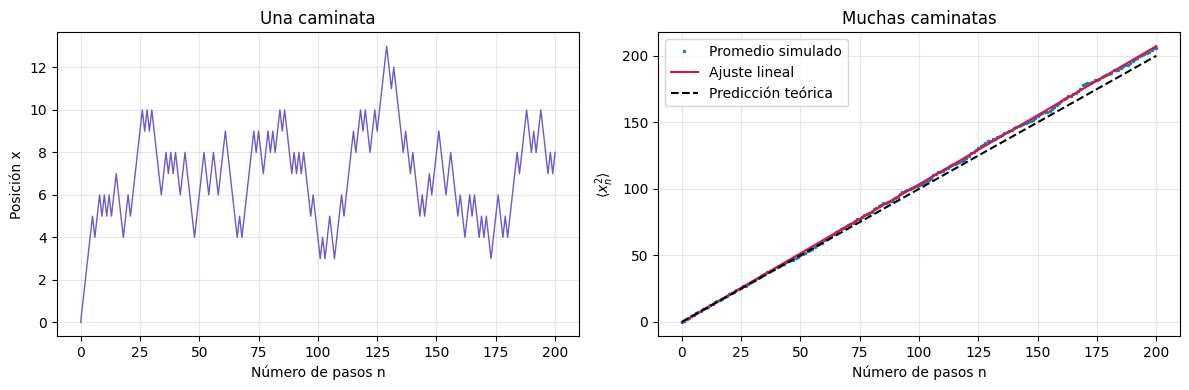

Pendiente=1.03839; intercepto=-0.40870
D estimado=0.51919; D teórico=0.50000 (longitud²/tiempo)


In [3]:
import random
import matplotlib.pyplot as plt

# --- Parámetros del experimento ---
K, N = 2000, 200            # caminantes y pasos por caminante
a, delta_t = 1.0, 1.0       # longitud de paso e intervalo de tiempo
semilla = 2026              # semilla del resultado entregado

# --- Simulación y ajuste lineal de <x_n^2> frente a n ---
media_x, media_x2 = simular_caminatas(K, N, a, semilla)
pasos = list(range(N + 1))
pendiente, intercepto = ajuste_lineal(pasos, media_x2)

# --- Coeficiente de difusión: estimado (del ajuste) y teórico ---
D_estimado = pendiente / (2 * delta_t)
D_teorico = (a * a) / (2 * delta_t)
ajuste = [pendiente * n + intercepto for n in pasos]   # recta ajustada, para graficar

# --- Una trayectoria individual, para comparar con el promedio ---
trayectoria = caminar(N, a, random.Random(2027))

# --- Guardar los resultados en un archivo CSV ---
with open("caminata_difusion.csv", "w", encoding="utf-8") as archivo:
    archivo.write("n,media_x,media_x2,ajuste\n")
    for n in pasos:
        archivo.write(f"{n},{media_x[n]},{media_x2[n]},{ajuste[n]}\n")

# --- Figura: trayectoria individual (izquierda) y promedios (derecha) ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(pasos, trayectoria, color="slateblue", linewidth=1)
ax1.set(xlabel="Número de pasos n", ylabel="Posición x", title="Una caminata")
ax2.plot(pasos, media_x2, ".", markersize=3, label="Promedio simulado")
ax2.plot(pasos, ajuste, color="crimson", label="Ajuste lineal")
ax2.plot(pasos, [n*a*a for n in pasos], "--", color="black", label="Predicción teórica")
ax2.set(xlabel="Número de pasos n", ylabel=r"$\langle x_n^2\rangle$", title="Muchas caminatas")
for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
ax2.legend()
plt.tight_layout()
plt.savefig("caminata_difusion.png", dpi=180, bbox_inches="tight")
plt.show()

# --- Resumen numérico ---
print(f"Pendiente={pendiente:.5f}; intercepto={intercepto:.5f}")
print(f"D estimado={D_estimado:.5f}; D teórico={D_teorico:.5f} (longitud²/tiempo)")

## Parte D — Efecto de un mal generador sobre el coeficiente de difusión

En las diapositivas se mostró que el generador congruencial $(a,c,M,r_1)=(57,1,256,10)$ produce pares consecutivos alineados en una rejilla. Ahora se medirá el efecto de ese defecto sobre **un resultado físico**: el coeficiente de difusión $D$.

La clase `GeneradorLCG` de la celda siguiente ya está completa. Tiene un método `random()` que devuelve $r_i/M$, igual que `random.Random`; por eso puede entregarse directamente a `simular_caminatas` mediante el argumento `generador`. Ejecútela sin modificarla.

### Actividades

1. Ejecute la simulación con $K=2000$, $N=200$, $a=1$, $\Delta t=1$ usando tres generadores: `random.Random(2026)`, el LCG deficiente `GeneradorLCG(57, 1, 256, 10)` y el LCG de parámetros de `drand48`, `GeneradorLCG(0x5DEECE66D, 11, 2**48, 10)`.
2. Ajuste una recta a $\langle x_n^2\rangle$ en cada caso con `ajuste_lineal` y calcule el coeficiente de difusión $D$. Guarde los resultados en `D_lcg_malo` y `D_drand48`.
3. Represente $\langle x_n^2\rangle$ frente a $n$ para los tres generadores en una misma figura.
4. Guarde en `trayectoria_lcg_larga` **una sola** caminata de 1024 pasos con el LCG deficiente e imprima la posición en $n = 0, 256, 512, 768, 1024$. Explique el resultado usando el período del generador.
5. Responda: ¿qué coeficiente de difusión habría reportado un investigador que usara este generador sin probarlo? ¿Por qué las pruebas de media y de pares consecutivos del Ejercicio 1 son necesarias antes de simular?


In [4]:
class GeneradorLCG:
    def __init__(self, a, c, m, semilla):
        """
        Inicializa el generador lineal congruencial (LCG):
        X_{i+1} = (a * X_i + c) % m
        """
        self.a = a
        self.c = c
        self.m = m
        self.estado = semilla

    def random(self):
        """
        Genera el siguiente número pseudoaleatorio normalizado en el intervalo [0.0, 1.0).
        """
        self.estado = (self.a * self.estado + self.c) % self.m
        return self.estado / self.m

valores de D:
D con random.Random : 0.5192
D con LCG deficiente: 0.0862
D con LCG drand48   : 0.4855   (teórico 0.5)

Grafica:


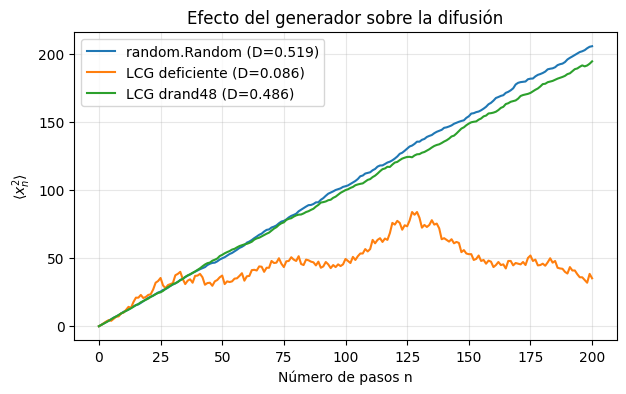


valores posiciones:
Posiciones en n = 0, 256, 512, 768, 1024:
[0.0, 0.0, 0.0, 0.0, 0.0]


In [ ]:
# --- Parámetros comunes a los tres experimentos ---
K_gen, N_gen = 2000, 200
pasos_gen = list(range(N_gen + 1))

# --- Misma simulación con tres generadores distintos ---
_, x2_bueno = simular_caminatas(K_gen, N_gen, 1.0, 2026)                            # random.Random
_, x2_malo = simular_caminatas(K_gen, N_gen, 1.0, None, generador=GeneradorLCG(57, 1, 256, 10))     # LCG (57, 1, 256, 10)
_, x2_drand48 = simular_caminatas(K_gen, N_gen, 1.0, None, generador=GeneradorLCG(0x5DEECE66D, 11, 2**48, 10))  # LCG drand48

# --- Pendiente de <x_n^2> para cada generador ---
m_bueno, _ = ajuste_lineal(pasos_gen, x2_bueno)
m_malo, _ = ajuste_lineal(pasos_gen, x2_malo)
m_drand48, _ = ajuste_lineal(pasos_gen, x2_drand48)


print('valores de D:')
# --- Coeficiente de difusión D = pendiente / (2 dt), con dt = 1 ---
D_bueno = m_bueno / 2
D_lcg_malo = m_malo / 2
D_drand48 = m_drand48 / 2

print(f"D con random.Random : {D_bueno:.4f}")
print(f"D con LCG deficiente: {D_lcg_malo:.4f}")
print(f"D con LCG drand48   : {D_drand48:.4f}   (teórico 0.5)")

print()
print('Grafica:')
# --- Gráfica comparativa ---
plt.figure(figsize=(7, 4))
plt.plot(pasos_gen, x2_bueno, label=f"random.Random (D={D_bueno:.3f})")
plt.plot(pasos_gen, x2_malo, label=f"LCG deficiente (D={D_lcg_malo:.3f})")
plt.plot(pasos_gen, x2_drand48, label=f"LCG drand48 (D={D_drand48:.3f})")
plt.xlabel("Número de pasos n")
plt.ylabel(r"$\langle x_n^2\rangle$")
plt.title("Efecto del generador sobre la difusión")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

print()
print('valores posiciones:')
# --- Una caminata larga con el LCG deficiente (actividad 4) ---
trayectoria_lcg_larga = caminar(1024, 1.0, GeneradorLCG(57, 1, 256, 10))
print("Posiciones en n = 0, 256, 512, 768, 1024:")
print([trayectoria_lcg_larga[n] for n in (0, 256, 512, 768, 1024)])

## Parte E — Difusión en unidades reales

Hasta ahora $a=1$ y $\Delta t=1$ en unidades arbitrarias. Para dar sentido físico al resultado, considere una molécula de oxígeno disuelta en agua a temperatura ambiente, cuyo coeficiente de difusión $D$ es aproximadamente

$$D_{\rm O_2}\approx 2\times10^{-9}\ \text{m}^2/\text{s}.$$

El modelo de caminata reproduce ese valor si la longitud del paso y el intervalo cumplen $D=a^2/(2\Delta t)$. El tiempo característico para que el desplazamiento cuadrático medio alcance $L^2$ es, en una dimensión,

$$t(L)\approx\frac{L^2}{2D}.$$

### Actividades

1. Con $\Delta t = 1\ \mu\text{s}$, calcule la longitud de paso `a_fisico` (en metros) que reproduce $D_{\rm O_2}$.
2. Convierta la pendiente `pendiente` obtenida en la Parte C (en unidades de $a^2$ por paso) a un coeficiente de difusión en m²/s: $D_{\rm sim} = m\,a_{\rm fisico}^2/(2\Delta t)$. Compárelo con $D_{\rm O_2}$.
3. Calcule `t_celula`, `t_mm` y `t_cm`: el tiempo para difundir $L = 10\ \mu\text{m}$ (el tamaño de una célula), $1$ mm y $1$ cm. Exprese cada uno en la unidad más legible (s, min, h).
4. Calcule también el tiempo para $L = 1$ m en agua quieta y expréselo en años.
5. ¿Cuántos pasos $N$ necesitaría la simulación para representar la difusión a lo largo de 1 cm con el paso `a_fisico`? Comente por qué, a escalas grandes, se usa la ecuación de difusión en lugar de simular cada paso.
6. Discuta brevemente: la difusión basta para transportar oxígeno dentro de una célula, pero ¿basta para mezclar un contaminante en un lago? ¿Qué otro mecanismo de transporte domina a escalas grandes?


**Interpretación:** este tiempo corresponde a una distancia raíz cuadrática media $x_{\mathrm{rms}}=L$. No es el tiempo en que todas las partículas alcanzan $L$, ni garantiza mezcla completa. El paso `a_fisico` es una longitud efectiva de este modelo: no se identifica necesariamente con la distancia entre colisiones moleculares. El valor de $D_{\rm O_2}$ se usa como dato aproximado del ejercicio; depende de las condiciones del medio.


In [5]:
import math

# --- Datos físicos ---
D_O2 = 2e-9          # m^2/s, coeficiente de difusión del oxígeno en agua (aprox.)
dt_fisico = 1e-6     # s, intervalo de tiempo entre pasos

# --- Longitud de paso y coeficiente de difusión simulado ---
a_fisico = math.sqrt(2 * D_O2 * dt_fisico)                 # m, despejado de D = a^2/(2 dt)
D_sim = pendiente * (a_fisico**2) / (2 * dt_fisico)         # m^2/s, a partir de la pendiente de la Parte C

# --- Tiempo característico de difusión ---
def tiempo_difusion(L, D):
    """Tiempo t = L^2/(2D) para alcanzar una distancia RMS L en una dimensión."""
    return (L**2) / (2 * D)

# --- Tiempos para distintas escalas de longitud ---
t_celula = tiempo_difusion(10e-6, D_O2)   # s, una célula (10 µm)
t_mm = tiempo_difusion(1e-3, D_O2)        # s, 1 mm
t_cm = tiempo_difusion(1e-2, D_O2)        # s, 1 cm
t_m = tiempo_difusion(1.0, D_O2)          # s, 1 m

# --- Número de pasos que exigiría simular 1 cm con el paso a_fisico ---
N_cm = (1e-2 / a_fisico)**2

# --- Resultados en unidades legibles ---
print(f"a = {a_fisico*1e9:.1f} nm;  D_sim = {D_sim:.3e} m^2/s  (referencia {D_O2:.1e})")
print(f"10 µm: {t_celula:.3g} s")
print(f"1 mm : {t_mm:.3g} s = {t_mm/60:.3g} min")
print(f"1 cm : {t_cm:.3g} s = {t_cm/3600:.3g} h")
print(f"1 m  : {t_m/(3600*24*365.25):.3g} años")
print(f"Pasos para 1 cm: {N_cm:.2e}")

a = 63.2 nm;  D_sim = 2.077e-09 m^2/s  (referencia 2.0e-09)
10 µm: 0.025 s
1 mm : 250 s = 4.17 min
1 cm : 2.5e+04 s = 6.94 h
1 m  : 7.92 años
Pasos para 1 cm: 2.50e+10


VERIFICACION PASS/FAIL

In [ ]:
# --- Bibliotecas para leer el CSV y comparar números reales ---
import csv
import math
from pathlib import Path

# --- Registro de resultados: imprime PASS/FAIL y guarda cada veredicto ---
veredictos = []
def informar(nombre, condicion, detalle=""):
    estado = "PASS" if condicion else "FAIL"
    veredictos.append(condicion)
    print(f"{estado} | {nombre}" + (f" — {detalle}" if detalle else ""))

# --- Generador de prueba: devuelve valores fijados de antemano ---
class RngControlado:
    def __init__(self, valores):
        self.valores = iter(valores)
    def random(self):
        return next(self.valores)

# --- Prueba 1: regla del paso (umbral en 0.5) ---
try:
    pasos_prueba = [generar_paso(RngControlado([u]), 2.0) for u in (0.0, 0.49, 0.5, 0.99)]
    informar("Regla del paso y umbral 0.5", pasos_prueba == [2.0, 2.0, -2.0, -2.0])
except Exception as exc:
    informar("Regla del paso y umbral 0.5", False, str(exc))

# --- Prueba 2: trayectoria con números controlados ---
try:
    posiciones_prueba = list(caminar(4, 2.0, RngControlado([0.1, 0.7, 0.2, 0.8])))
    informar("Trayectoria y posición inicial", posiciones_prueba == [0.0, 2.0, 0.0, 2.0, 0.0])
except Exception as exc:
    informar("Trayectoria y posición inicial", False, str(exc))

# --- Prueba 3: ajuste lineal con datos exactos ---
try:
    m_prueba, b_prueba = ajuste_lineal([0, 1, 2, 3], [2, 5, 8, 11])
    informar("Ajuste lineal con datos conocidos", math.isclose(m_prueba, 3.0, abs_tol=1e-10) and math.isclose(b_prueba, 2.0, abs_tol=1e-10))
except Exception as exc:
    informar("Ajuste lineal con datos conocidos", False, str(exc))

# --- Pruebas 4-7: estructura, reproducibilidad, simetría y crecimiento difusivo ---
try:
    mx1, mx21 = simular_caminatas(2000, 100, 1.0, 12345)
    mx2, mx22 = simular_caminatas(2000, 100, 1.0, 12345)
    estructura = (len(mx1) == len(mx21) == 101 and
                  math.isclose(mx1[0], 0.0) and math.isclose(mx21[0], 0.0) and
                  all(math.isfinite(float(v)) for v in list(mx1) + list(mx21)))
    informar("Longitud, origen y valores finitos", estructura)
    informar("Reproducibilidad con la misma semilla", list(mx1) == list(mx2) and list(mx21) == list(mx22))
    if estructura:
        exactitud_media = all(abs(mx1[n]) <= 0.20*math.sqrt(n) + 0.1 for n in (25, 50, 100))
        informar("Media de posición compatible con simetría", exactitud_media)
        m_test, _ = ajuste_lineal(list(range(101)), mx21)
        informar("Crecimiento difusivo promedio", math.isfinite(m_test) and abs(m_test - 1.0) < 0.15, f"pendiente={m_test:.4f}")
    else:
        informar("Media de posición compatible con simetría", False)
        informar("Crecimiento difusivo promedio", False)
except Exception as exc:
    for nombre in ("Longitud, origen y valores finitos", "Reproducibilidad con la misma semilla", "Media de posición compatible con simetría", "Crecimiento difusivo promedio"):
        informar(nombre, False, str(exc))

# --- Prueba 8: parámetros inválidos deben producir ValueError ---
try:
    rechazos = []
    for llamada in (lambda: caminar(-1, 1.0, random.Random(1)),
                    lambda: simular_caminatas(0, 10, 1.0, 1),
                    lambda: ajuste_lineal([1, 1], [2, 3])):
        try:
            llamada()
            rechazos.append(False)
        except ValueError:
            rechazos.append(True)
    informar("Parámetros y ajuste degenerado rechazados", all(rechazos))
except Exception as exc:
    informar("Parámetros y ajuste degenerado rechazados", False, str(exc))

# --- Prueba 9: archivo CSV completo y consistente ---
try:
    datos = list(csv.DictReader(open("caminata_difusion.csv", encoding="utf-8")))
    columnas = set(datos[0]) if datos else set()
    valido = (len(datos) == N + 1 and columnas == {"n", "media_x", "media_x2", "ajuste"}
              and [int(fila["n"]) for fila in datos] == list(range(N+1)))
    if valido:
        valido = all(math.isclose(float(fila["media_x2"]), float(media_x2[i]), abs_tol=1e-10)
                     and math.isclose(float(fila["ajuste"]), pendiente*i + intercepto, abs_tol=1e-9)
                     for i, fila in enumerate(datos))
    informar("CSV completo y consistente con el ajuste", valido)
except Exception as exc:
    informar("CSV completo y consistente con el ajuste", False, str(exc))

# --- Prueba 10: conversión de la pendiente al coeficiente de difusión ---
try:
    correcto_D = (math.isclose(D_estimado, pendiente/(2*delta_t), rel_tol=1e-10, abs_tol=1e-10)
                   and math.isclose(D_teorico, a*a/(2*delta_t), rel_tol=1e-10, abs_tol=1e-10))
    informar("Conversión de la pendiente al coeficiente de difusión", correcto_D)
except Exception as exc:
    informar("Conversión de la pendiente al coeficiente de difusión", False, str(exc))

# --- Prueba 11: simular_caminatas acepta un generador externo (Parte D) ---
try:
    _, x2_ctrl = simular_caminatas(1, 2, 1.0, None, generador=RngControlado([0.1, 0.7]))
    informar("simular_caminatas acepta un generador externo", [float(t) for t in x2_ctrl] == [0.0, 1.0, 0.0])
except Exception as exc:
    informar("simular_caminatas acepta un generador externo", False, str(exc))

# --- Pruebas 12-13: coeficiente de difusión con el LCG deficiente y con drand48 ---
try:
    informar("LCG deficiente: resultado del experimento especificado", math.isfinite(D_lcg_malo) and math.isclose(D_lcg_malo, 0.08623725432244717, rel_tol=1e-6, abs_tol=1e-8), f"D_lcg_malo={D_lcg_malo:.4f}")
    informar("LCG drand48: coeficiente de difusión compatible con 0.5", abs(D_drand48 - 0.5) < 0.075, f"D_drand48={D_drand48:.4f}")
except Exception as exc:
    informar("LCG deficiente: resultado del experimento especificado", False, str(exc))
    informar("LCG drand48: coeficiente de difusión compatible con 0.5", False, str(exc))

# --- Pruebas 14-15: unidades reales (Parte E) ---
try:
    ok_a = math.isclose(a_fisico, math.sqrt(2*D_O2*dt_fisico), rel_tol=1e-9)
    ok_Dsim = math.isclose(D_sim, pendiente*a_fisico**2/(2*dt_fisico), rel_tol=1e-9)
    informar("Paso físico y coeficiente de difusión en m²/s", ok_a and ok_Dsim, f"a={a_fisico*1e9:.1f} nm, D_sim={D_sim:.2e} m²/s")
    ok_t = (math.isclose(t_celula, 0.025, rel_tol=1e-9) and math.isclose(t_cm, 2.5e4, rel_tol=1e-9)
            and math.isclose(t_mm, 250.0, rel_tol=1e-9) and math.isclose(t_m, 2.5e8, rel_tol=1e-9)
            and math.isclose(N_cm, (1e-2/a_fisico)**2, rel_tol=1e-6))
    informar("Tiempos de difusión y número de pasos", ok_t, f"t(10 µm)={t_celula:.3g} s, t(1 cm)={t_cm/3600:.2f} h")
except Exception as exc:
    informar("Paso físico y coeficiente de difusión en m²/s", False, str(exc))
    informar("Tiempos de difusión y número de pasos", False, str(exc))

# Prueba determinista de la caminata larga: no llama a las funciones del estudiante.
try:
    estado_ref = 10
    x_ref = 0.0
    recorrido_ref = [x_ref]
    for _ in range(1024):
        estado_ref = (57*estado_ref + 1) % 256
        x_ref += 1.0 if estado_ref/256 < 0.5 else -1.0
        recorrido_ref.append(x_ref)
    informar("Caminata larga con LCG: trayectoria y retornos periódicos",
             list(trayectoria_lcg_larga) == recorrido_ref)
except Exception as exc:
    informar("Caminata larga con LCG: trayectoria y retornos periódicos", False, str(exc))

# --- Prueba 16: la figura fue guardada ---
figura = Path("caminata_difusion.png")
informar("Figura generada", figura.is_file() and figura.stat().st_size > 1000)
# --- Resumen final ---
print(f"Resumen: {sum(veredictos)}/{len(veredictos)} PASS")

PASS | Regla del paso y umbral 0.5
PASS | Trayectoria y posición inicial
PASS | Ajuste lineal con datos conocidos
PASS | Longitud, origen y valores finitos
PASS | Reproducibilidad con la misma semilla
PASS | Media de posición compatible con simetría
PASS | Crecimiento difusivo promedio — pendiente=1.0147
PASS | Parámetros y ajuste degenerado rechazados
PASS | CSV completo y consistente con el ajuste
PASS | Conversión de la pendiente al coeficiente de difusión
PASS | simular_caminatas acepta un generador externo
PASS | LCG deficiente: resultado del experimento especificado — D_lcg_malo=0.0862
PASS | LCG drand48: coeficiente de difusión compatible con 0.5 — D_drand48=0.4855
PASS | Paso físico y coeficiente de difusión en m²/s — a=63.2 nm, D_sim=2.08e-09 m²/s
PASS | Tiempos de difusión y número de pasos — t(10 µm)=0.025 s, t(1 cm)=6.94 h
PASS | Caminata larga con LCG: trayectoria y retornos periódicos
PASS | Figura generada
Resumen: 17/17 PASS
